# Análise exploratória com foco em negócio

Este notebook responde a quatro perguntas de negócio: que fatores pesam mais na satisfação, o que mais gera detratores, se existe um ponto de ruptura na experiência do cliente e que tipo de cliente tende a ter NPS mais alto ou mais baixo. A análise usa a base tratada, só com os pedidos de treino: os de teste ficam reservados para avaliar o modelo e as regras simples sem viés (D-11).

Três regras valem para todo o notebook. Grupos se comparam pela proporção de detratores e pelo NPS, nunca pela nota média (D-02). Os achados descrevem associação, não causa. E, como a base é simulada (D-10), cada padrão vale para esta base e entra nas recomendações como hipótese a validar com dados reais.

In [ ]:
# Importações
from functools import partial

from loguru import logger
from matplotlib.patches import Patch
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.tree import DecisionTreeClassifier
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportion_confint

# Logs do projeto desligados para não gravar caminhos da máquina local nas saídas
logger.disable("src")

from src.analysis import (
    bootstrap_statistic,
    breakpoint_test,
    estimate_contrast,
    excess_over_additive,
    factor_ranking,
    failure_flags,
    invert_verdict,
    nps_gain,
    nps_of,
    problem_impact,
    quartiles,
    ranking_metrics,
    rate_table,
    standardized_share,
    tree_leaves,
    verdict_adjustment,
    verdict_breakpoint,
    verdict_effect,
    verdict_share,
    within_strata,
)
from src.config import RANDOM_SEED
from src.features import LONG_RESOLUTION_DAYS, classify_nps, load_processed_data
from src.plots import (
    ACCENT,
    CATEGORY_COLORS,
    plot_impact_frequency,
    plot_rate,
    plot_rate_heatmaps,
    plot_rates,
    save_figure,
    set_style,
)
from src.split import TRAIN, split_train_test

set_style()

# Só os pedidos de treino; o teste fica intocado até a avaliação do modelo (D-11)
processed = load_processed_data()
train = processed[split_train_test(processed) == TRAIN].copy()
print(f"{len(train)} pedidos de treino, de {len(processed)}")


2000 pedidos de treino, de 2500


## 1. A variável-alvo

Distribuição da nota, proporção de detratores, neutros e promotores e NPS do treino. A proporção de detratores também fixa as referências das métricas da D-03: um modelo que dá o mesmo risco a todos tem PR-AUC igual a ela, e a captura numa lista com os 20% de maior risco tem um teto, porque a lista não comporta todos os detratores quando eles passam de 20% dos pedidos.

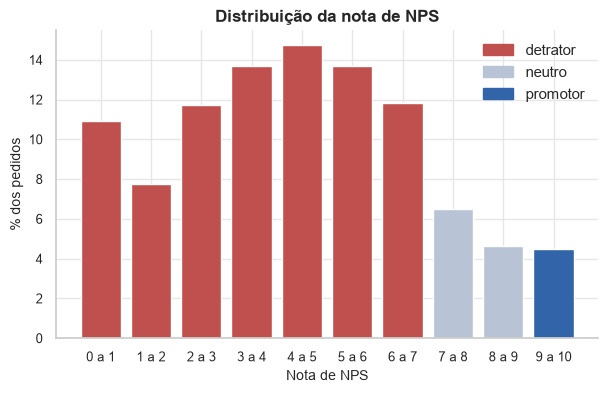

detratores (%)                 84.35
neutros (%)                    11.15
promotores (%)                  4.50
NPS                           -79.85
PR-AUC do modelo ingênuo        0.84
teto da captura no topo (%)    23.71
dtype: float64

In [ ]:
# Nota em faixas de um ponto, coloridas pela categoria do NPS (D-05)
score_band = np.floor(train["nps_score"]).clip(upper=9).astype(int)
share_by_band = score_band.value_counts(normalize=True).sort_index().mul(100)
band_category = classify_nps(share_by_band.index.to_series())

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(share_by_band.index, share_by_band, color=band_category.map(CATEGORY_COLORS).tolist())
ax.set_xticks(share_by_band.index, [f"{band} a {band + 1}" for band in share_by_band.index])
ax.set_xlabel("Nota de NPS")
ax.set_ylabel("% dos pedidos")
ax.set_title("Distribuição da nota de NPS")
ax.legend(handles=[Patch(color=c, label=n) for n, c in CATEGORY_COLORS.items()], frameon=False)
save_figure(fig, "01_distribuicao_da_nota")
plt.show()

shares = train["nps_category"].value_counts(normalize=True).mul(100)
prevalence = train["is_detractor"].mean()
pd.Series(
    {
        "detratores (%)": shares["detrator"],
        "neutros (%)": shares["neutro"],
        "promotores (%)": shares["promotor"],
        "NPS": nps_of(train["nps_category"]),
        "PR-AUC do modelo ingênuo": prevalence,
        "teto da captura no topo (%)": 100 * min(1, 0.2 / prevalence),
    }
).round(2)


**A insatisfação é generalizada: mais de oito em cada dez clientes do treino dão nota abaixo de 7, e o NPS fica perto do piso da escala.** As notas se espalham por toda a faixa de detrator, com pico no meio da escala, e rareiam a partir de 7: os neutros são pouco mais de um em cada dez clientes, e os promotores, menos de um em cada vinte. Nas métricas da D-03, sobra pouca distância entre um modelo sem informação e um perfeito: dar o mesmo risco a todos já garante PR-AUC alta, e a lista com os 20% de maior risco, mesmo perfeita, alcança menos de um em cada quatro detratores, contra um em cada cinco de uma lista sorteada.

## 2. O valor do NPS na própria base

Se a nota reflete comportamento, a recompra em 30 dias deve subir de detrator para promotor. E, se CSAT e NPS medem a mesma satisfação, as duas notas devem andar juntas. Recompra e CSAT ficam fora do modelo (D-06); aqui servem para validar a variável-alvo.

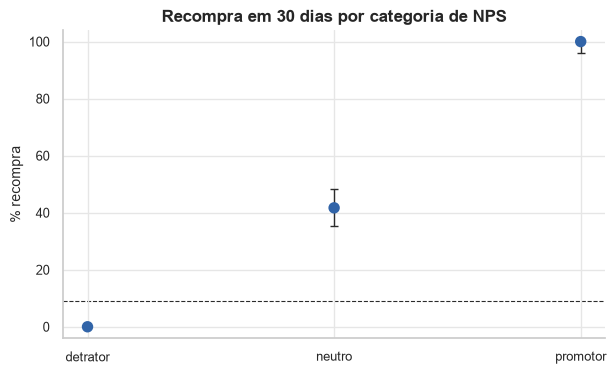

Correlação de Spearman entre CSAT e nota de NPS: 0.58 (p-valor 5e-178)


,pedidos,% recompra,IC inferior,IC superior,CSAT mediano
nps_category,,,,,
detrator,1687,0.0,0.0,0.2,2.3
neutro,223,41.7,35.4,48.3,5.2
promotor,90,100.0,95.9,100.0,6.3


In [ ]:
repurchase = rate_table(train, "nps_category", target="repeat_purchase_30d").drop(columns="NPS")

fig, ax = plt.subplots(figsize=(7, 4))
plot_rate(
    repurchase,
    ax=ax,
    reference=100 * train["repeat_purchase_30d"].mean(),
    title="Recompra em 30 dias por categoria de NPS",
)
save_figure(fig, "02_recompra_por_categoria")
plt.show()

rho, p_value = stats.spearmanr(train["csat_internal_score"], train["nps_score"])
print(f"Correlação de Spearman entre CSAT e nota de NPS: {rho:.2f} (p-valor {p_value:.1g})")
csat = train.groupby("nps_category", observed=True)["csat_internal_score"].median()
repurchase.assign(**{"CSAT mediano": csat}).round(1)


**A recompra acompanha a categoria de NPS sem exceção: nenhum detrator volta a comprar em até 30 dias, e todos os promotores voltam.** Entre os neutros, cerca de quatro em cada dez recompram, e o CSAT sobe na mesma ordem das categorias, com associação moderada à nota, o que torna real o risco de vazamento que o mantém fora do modelo (D-06). A nota se sustenta como variável-alvo, embora uma separação tão exata seja mais um sinal da base simulada (D-10) do que evidência do valor do NPS numa operação real.